## Purpose of This Notebook

This notebook serves as an exploratory tool for examining the log files produced during the horse behavioural experiments conducted in October and November 2023. It facilitates the experimentation with text parsing techniques on the files before they are imported into a database. The primary objectives are:


> To conduct experiments with regular expressions ([`regex`](https://docs.python.org/3/howto/regex.html)) aimed at extracting pertinent data and fields from the log files.

In [1]:
# | echo: false

from pprint import pprint
from typing import List

import pandas as pd
from loguru import logger

from horse_logic.logfiles import (
    EventCB,
    ExperimentCB,
    Logfile,
    Logs,
    ResponseCB,
    TrialCB,
)
from horse_logic.project import Project
from horse_logic.subject import Subject
from horse_logic.utils import display_class_definition


### Setup project & directories


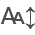

INFO     | Data directory: /Users/mjboothaus/code/github/databooth/horse-logic/data
INFO     | Data directory purpose: Parent directory for raw and processed data
INFO     | Sql directory: /Users/mjboothaus/code/github/databooth/horse-logic/sql
INFO     | Sql directory purpose: Store SQL scripts
INFO     | Output directory: /Users/mjboothaus/code/github/databooth/horse-logic/notebooks/results/CB
INFO     | Output directory purpose: Store output files and results by experiment type
INFO     | Logfiles directory: /Users/mjboothaus/code/github/databooth/horse-logic/data/results/zips/cb_data
INFO     | Logfiles directory purpose: Store for the raw log files
INFO     | Notebooks directory: /Users/mjboothaus/code/github/databooth/horse-logic/notebooks
INFO     | Notebooks directory purpose: Jupyter notebooks for performing analysis
INFO     | Existing database file deleted: /Users/mjboothaus/code/github/databooth/horse-logic/data/Experiments_CB_2023_Q4.ddb
INFO     | Database file path: /Use

In [2]:
# | echo: false

project = Project(experiment_type="CB", table_page_length=25)
project.create_tables_from_sql_file("create_cb_experiment_tables_ddb.sql")
con = project.get_db_connection()

EXPERIMENT_TYPE = project.experiment_type

DATA_DIR = project.data_dir
LOGFILES_DIR = project.logfiles_dir
NOTEBOOK_DIR = project.notebooks_dir
OUTPUT_DIR = project.output_dir

In [3]:
### Get Subject info

In [4]:
# | echo: false

subject = Subject(project)

subject_df = subject.get_subject_info()

INFO     | Loaded subject info from: /Users/mjboothaus/code/github/databooth/horse-logic/docs/from_CH/Cohort data for MB.xlsx
INFO     | Subject count: 22
INFO     | Sorted subject names:
	apollo, ash, atom, bonnie, clover, dodge, dougie, dusty, filly, freya, george, gio, jelly, molly, mowgli, myrtle, 
	nix, olive, pumba, smudge, teddy, yoshi


#### Load logfiles from CSV list of included files

As determined in `logfiles-reconciliation-CB.ipynb`

In [5]:
# | echo: false

logs = Logs(path=LOGFILES_DIR)
logs.load_specific_logfiles_from_csv(OUTPUT_DIR / "all_included_files.csv")

In [6]:
# | echo: false

logger.info(logs)

INFO     | Logs: 184 log files in /Users/mjboothaus/code/github/databooth/horse-logic/data/results/zips/cb_data


### Explore `regex` parsing of a single example log file

Analysis code is in `logfiles.py`. Explore parsing log information for specific example defined below.

In [7]:
# | echo: false

# Choose one of the file names for testing

log_eg = [log.file_name for log in logs.logfiles][0]

# Or override with specific log file

# log_eg = "Experiment_2023-11-15T00:39:50.244185_clover_nan_Test Type 1.log"

log_eg = "Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.log"
log_eg = "Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.log"


In [8]:
# | echo: false

logfile_eg = f"{logs.path}/{log_eg}"

In [9]:
# | echo: false

_ = project.create_markdown_link(logfile_eg)

[/Users/mjboothaus/code/github/databooth/horse-logic/data/results/zips/cb_data/Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.log](data/results/zips/cb_data/Experiment_2023-10-06T12%3A49%3A44.174442_atom_2_Training%20-%20fixed.log)

In [10]:
# | echo: false

# Load example log file into Logfile class for processing
log_eg = Logfile(logfile_eg)

In [11]:
# | echo: false

print(f"Example log file for regex parsing: {log_eg.file_name}")

Example log file for regex parsing: Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.log


### Data structures

These are created as `dataclasses` in Python (in `logfiles.py`) and TABLES in SQL (`sql/create_experiment_tables_ddb.sql`).

#### Experiment table

In [12]:
# | echo: false

display_class_definition(ExperimentCB)

```@dataclass
class ExperimentCB:
    ExperimentID: int
    Cohort: str
    SubjectName: str
    SubjectNumber: int
    SessionNumber: int
    SessionType: str  # "training" or "test"
    ExperimentType: str
    Direction: str  # New field
    Comment: Optional[str]
    DateTime: datetime
    LogFileName: str
    Parameters: Dict
```

#### e.g. Parse experiment details and comment from log file

In [13]:
# | echo: false

pprint(log_eg.parse_filename_components_cog_bias())

ExperimentCB(ExperimentID=None,
             Cohort=None,
             SubjectName='atom',
             SubjectNumber=None,
             SessionNumber=2,
             SessionType='test',
             ExperimentType='Training - fixed',
             Direction=None,
             Comment='First session',
             DateTime=datetime.datetime(2023, 10, 6, 12, 49, 44, 174442),
             LogFileName='Experiment_2023-10-06T12:49:44.174442_atom_2_Training '
                         '- fixed.log',
             Parameters=None)


#### Trials and Events tables

In [14]:
log_eg.parse_filename_components_cog_bias().LogFileName

'Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.log'

In [15]:
# | echo: false

display_class_definition(TrialCB)

```@dataclass
class TrialCB:
    TrialID: int
    ExperimentID: int
    TrialNumber: int
    ResponseType: str
    TrialSubType: str
    CriterionType: Optional[str]
    CriterionCount: Optional[float]
    TrialStartTime: datetime
    TrialEndTime: datetime
    # Direction and SessionType fields removed
```

In [16]:
# | echo: false

display_class_definition(ResponseCB)

```@dataclass
class ResponseCB:
    ResponseID: int
    TrialID: int
    ResponseTime: Optional[float]
    EventDateTime: datetime
```

In [17]:
# | echo: false

display_class_definition(EventCB)

```@dataclass
class EventCB:
    EventID: int
    TrialID: int
    EventType: str
    EventTime: datetime
    ElapsedTime: float
```

#### e.g. Parsing of trials and events info from an example log file

In [18]:
log_eg.parse_comments()

'First session'

In [19]:
# | echo: false

experiment_df, trials_df, responses_df, events_df = log_eg.parse_trials_and_events_cog_bias()


In [20]:
experiment_df

ExperimentID Cohort SubjectName SubjectNumber  SessionNumber SessionType  \
0         None   None        atom          None              2        test   

     ExperimentType Direction        Comment                   DateTime  \
0  Training - fixed      None  First session 2023-10-06 12:49:44.174442   

                                         LogFileName Parameters  
0  Experiment_2023-10-06T12:49:44.174442_atom_2_T...       None

In [21]:
trials_df

TrialID ExperimentID  TrialNumber ResponseType TrialSubType CriterionType  \
0         1         None            1           GO            P      positive   
1         2         None            2           GO            P      positive   
2         3         None            3           GO            P      positive   
3         4         None            4           GO            P      positive   
4         5         None            5           GO            P      positive   
5         6         None            6           GO            P      positive   
6         7         None            7           GO            P          None   
7         8         None            8           GO            P      positive   
8         9         None            9           GO            P      positive   
9        10         None           10           GO            P      positive   
10       11         None           11           GO            N          None   
11       12         None           12           GO            N          None   
12       13         None           13           GO            N          None   
13       14         None           14           GO            N          None   
14       15         None           15         NOGO            N      negative   
15       16         None           16         NOGO            N      negative   
16       17         None           17         NOGO            N      negative   
17       18         None           18         NOGO            N      negative   
18       19         None           19         NOGO            N      negative   

    CriterionCount             TrialStartTime               TrialEndTime  
0              1.0 2023-10-06 12:50:36.543201 2023-10-06 12:51:42.291332  
1              2.0 2023-10-06 12:51:53.268573 2023-10-06 12:52:51.630356  
2              3.0 2023-10-06 12:53:01.531667 2023-10-06 12:54:26.634533  
3              4.0 2023-10-06 12:54:37.725440 2023-10-06 12:55:24.875527  
4              5.0 2023-10-06 12:55:33.610711 2023-10-06 12:56:12.517965  
5              6.0 2023-10-06 12:56:22.610633 2023-10-06 12:56:48.216922  
6              NaN 2023-10-06 12:57:35.760606 2023-10-06 12:58:31.699808  
7              7.0 2023-10-06 12:58:39.385306 2023-10-06 12:59:08.053932  
8              8.0 2023-10-06 12:59:17.085578 2023-10-06 12:59:46.129396  
9              9.0 2023-10-06 12:59:56.947294 2023-10-06 13:00:32.579564  
10             NaN 2023-10-06 13:00:51.172825 2023-10-06 13:01:20.989600  
11             NaN 2023-10-06 13:01:30.495559 2023-10-06 13:01:50.179606  
12             NaN 2023-10-06 13:02:23.942294 2023-10-06 13:02:43.702448  
13             NaN 2023-10-06 13:03:09.516276 2023-10-06 13:03:28.896875  
14             1.0 2023-10-06 13:04:28.896964 2023-10-06 13:04:47.236090  
15             2.0 2023-10-06 13:05:47.236139 2023-10-06 13:06:05.555654  
16             3.0 2023-10-06 13:07:05.555701 2023-10-06 13:07:31.725137  
17             4.0 2023-10-06 13:08:31.725067 2023-10-06 13:08:54.660715  
18             5.0 2023-10-06 13:09:54.660676 2023-10-06 13:09:54.660676

In [22]:
responses_df

ResponseID  TrialID  ResponseTime              EventDateTime
0            1        1     17.670339 2023-10-06 12:50:36.543201
1            2        2     10.977220 2023-10-06 12:51:53.268573
2            3        3      9.901265 2023-10-06 12:53:01.531667
3            4        4     11.090858 2023-10-06 12:54:37.725440
4            5        5      8.735194 2023-10-06 12:55:33.610711
5            6        6     10.093112 2023-10-06 12:56:22.610633
6            7        7     47.543691 2023-10-06 12:57:35.760606
7            8        8      7.686065 2023-10-06 12:58:39.385306
8            9        9      9.031617 2023-10-06 12:59:17.085578
9           10       10     10.817912 2023-10-06 12:59:56.947294
10          11       11     18.593252 2023-10-06 13:00:51.172825
11          12       12      9.505987 2023-10-06 13:01:30.495559
12          13       13     33.762633 2023-10-06 13:02:23.942294
13          14       14     25.813766 2023-10-06 13:03:09.516276

In [23]:
events_df

EventID  TrialID                                          EventType  \
0         1        1  GO for Trial 1 - P - positive - response time ...   
1         2        1              Green button pressed - horse released   
2         3        2  GO for Trial 2 - P - positive - response time ...   
3         4        2              Green button pressed - horse released   
4         5        3  GO for Trial 3 - P - positive - response time ...   
5         6        3              Green button pressed - horse released   
6         7        4  GO for Trial 4 - P - positive - response time ...   
7         8        4              Green button pressed - horse released   
8         9        5  GO for Trial 5 - P - positive - response time ...   
9        10        5              Green button pressed - horse released   
10       11        6  GO for Trial 6 - P - positive - response time ...   
11       12        6              Green button pressed - horse released   
12       13        7  GO for Trial 7 - P - positive - response time ...   
13       14        7              Green button pressed - horse released   
14       15        8  GO for Trial 8 - P - positive - response time ...   
15       16        8              Green button pressed - horse released   
16       17        9  GO for Trial 9 - P - positive - response time ...   
17       18        9              Green button pressed - horse released   
18       19       10  GO for Trial 10 - P - positive - response time...   
19       20       10              Green button pressed - horse released   
20       21       11  GO for Trial 11 - N - negative - response time...   
21       22       11              Green button pressed - horse released   
22       23       12  GO for Trial 12 - N - negative - response time...   
23       24       12              Green button pressed - horse released   
24       25       13  GO for Trial 13 - N - negative - response time...   
25       26       13              Green button pressed - horse released   
26       27       14  GO for Trial 14 - N - negative - response time...   
27       28       14              Green button pressed - horse released   
28       29       15  NOGO for Trial 15 - N - negative - negative cr...   
29       30       15              Green button pressed - horse released   
30       31       16  NOGO for Trial 16 - N - negative - negative cr...   
31       32       16              Green button pressed - horse released   
32       33       17  NOGO for Trial 17 - N - negative - negative cr...   
33       34       17              Green button pressed - horse released   
34       35       18  NOGO for Trial 18 - N - negative - negative cr...   
35       36       18              Green button pressed - horse released   
36       37       19  NOGO for Trial 19 - N - negative - negative cr...   

                    EventTime  ElapsedTime  
0  2023-10-06 12:50:36.543201    28.524709  
1  2023-10-06 12:51:42.291332    94.272840  
2  2023-10-06 12:51:53.268573   105.250081  
3  2023-10-06 12:52:51.630356   163.611864  
4  2023-10-06 12:53:01.531667   173.513175  
5  2023-10-06 12:54:26.634533   258.616041  
6  2023-10-06 12:54:37.725440   269.706948  
7  2023-10-06 12:55:24.875527   316.857035  
8  2023-10-06 12:55:33.610711   325.592219  
9  2023-10-06 12:56:12.517965   364.499473  
10 2023-10-06 12:56:22.610633   374.592141  
11 2023-10-06 12:56:48.216922   400.198430  
12 2023-10-06 12:57:35.760606   447.742114  
13 2023-10-06 12:58:31.699808   503.681316  
14 2023-10-06 12:58:39.385306   511.366814  
15 2023-10-06 12:59:08.053932   540.035440  
16 2023-10-06 12:59:17.085578   549.067086  
17 2023-10-06 12:59:46.129396   578.110904  
18 2023-10-06 12:59:56.947294   588.928802  
19 2023-10-06 13:00:32.579564   624.561072  
20 2023-10-06 13:00:51.172825   643.154333  
21 2023-10-06 13:01:20.989600   672.971108  
22 2023-10-06 13:01:30.495559   682.477067  
23 2023-10-06 13:01:50.179606   702.161114  
24 2023-10-06 13:02:23.94229

In [24]:
# | echo: false

# Export an example of the current parsing of the Trial/Event info for one sample experiment

project.export_data_to_csv(
    trials_df,
    OUTPUT_DIR / log_eg.file_name.replace(".log", ".csv"),
    "Example of parsing of the Trial/Event info for one sample experiment",
    trials_df.columns.to_list(),
)

project.export_data_to_xlsx(
    [experiment_df, trials_df, responses_df, events_df], 
    filepath = OUTPUT_DIR / log_eg.file_name.replace(".log", ".xlsx"),
    info_message = "Example of parsing of the Trial/Event info for one sample experiment",
)

INFO     | Example of parsing of the Trial/Event info for one sample experiment. 19 rows exported to CSV.


[results/CB/Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.csv](results/CB/Experiment_2023-10-06T12%3A49%3A44.174442_atom_2_Training%20-%20fixed.csv)

INFO     | Example of parsing of the Trial/Event info for one sample experiment. 71 total rows exported to XLSX across 4 sheets.


[results/CB/Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.xlsx](results/CB/Experiment_2023-10-06T12%3A49%3A44.174442_atom_2_Training%20-%20fixed.xlsx)

In [25]:
# | echo: false

# These files where all excluded by the parsing function (and have been added here explicitly)

## Override since CH exclude list from 16 Oct 2024 (see reconciliation notebook)

extra_excludes = []  # per Signal 18 Oct 2024 (no extra excludes for now)

In [26]:
# | echo: false

project.export_data_to_csv(
    pd.DataFrame(extra_excludes),
    OUTPUT_DIR / "extra_excludes.csv",
    "Additional log files excluded as bad data",
)

INFO     | Additional log files excluded as bad data. 0 rows exported to CSV.


[results/CB/extra_excludes.csv](results/CB/extra_excludes.csv)

In [27]:
# | echo: false

logfiles_to_process = [
    logfile.file_name for logfile in logs.logfiles if logfile.file_name not in extra_excludes
]

project.export_data_to_csv(
    pd.DataFrame(logfiles_to_process),
    OUTPUT_DIR / "logfiles-to-database.csv",
    "List of logfiles to be loaded to database",
)

INFO     | List of logfiles to be loaded to database. 184 rows exported to CSV.


[results/CB/logfiles-to-database.csv](results/CB/logfiles-to-database.csv)

### Bringing this all together and putting the data in `DuckDB` database

In [28]:
def parse_and_load_logfiles_to_database(logfiles_to_process: List[str], con, subject_df: pd.DataFrame, debug=False):
    skipped_logfiles = []
    experiment_id = 0
    trial_id = 0
    response_id = 0
    event_id = 0

    for log_filename in sorted(logfiles_to_process):
        logger.info(f"Processing: {experiment_id+1} - {logs.path}/{log_filename}")
        logfile = Logfile(f"{logs.path}/{log_filename}")

        try:
            exp_details = logfile.parse_filename_components_cog_bias()
        except ValueError as e:
            logger.warning(f"Skipping {log_filename}: {str(e)}")
            skipped_logfiles.append(log_filename)
            continue

        # Look up additional Experiment details from subject_df
        if exp_details.SubjectName:
            subject_row = subject_df[subject_df["subject_name"] == exp_details.SubjectName]
            if not subject_row.empty:
                exp_details.Cohort = subject_row["Cohort"].iloc[0]
                exp_details.SubjectNumber = int(subject_row["subject_number"].iloc[0])
                exp_details.Direction = subject_row["direction"].iloc[0]
            else:
                logger.warning(
                    f"Subject {exp_details.SubjectName} not found in subject_df. Skipping this file."
                )
                skipped_logfiles.append(log_filename)
                continue
        else:
            logger.warning(f"Unable to determine SubjectName for {log_filename}. Skipping this file.")
            skipped_logfiles.append(log_filename)
            continue

        exp_details.Parameters = logfile.parse_parameters()

        _, trials_df, responses_df, events_df = logfile.parse_trials_and_events_cog_bias()
        if trials_df is None or responses_df is None or events_df is None:
            logger.warning(f"Skipping {log_filename} due to parsing error")
            skipped_logfiles.append(log_filename)
            continue

        # Insert experiment record
        experiment_id += 1
        exp_details.ExperimentID = experiment_id
        logfile.insert_record_to_database(con, exp_details)
        last_experiment_id = logfile.get_last_insert_id(con, "ExperimentCBs")
        #assert experiment_id == last_experiment_id, f"Experiment ID mismatch: {experiment_id} != {last_experiment_id}"

        first_trial_id = trial_id
        first_response_id = response_id
        first_event_id = event_id

        # Process and insert Trials
        for i_trial, trial in trials_df.iterrows():
            trial_id += 1
            local_trial_id = trial['TrialID']
            trial['TrialID'] = trial_id
            trial['ExperimentID'] = exp_details.ExperimentID
            logfile.insert_record_to_cb_database(con, trial.to_dict(), "TrialCBs")
            #last_trial_id = logfile.get_last_insert_id(con, "TrialCBs")
            #assert trial_id == last_trial_id, f"Trial ID mismatch: {trial_id} != {last_trial_id}"

            # Process and insert Responses
            for i_response, response in responses_df[responses_df["TrialID"] == local_trial_id].iterrows():
                response_id += 1
                response['ResponseID'] = response_id
                response['TrialID'] = trial_id
                logfile.insert_record_to_cb_database(con, response.to_dict(), "ResponseCBs")
                last_response_id = logfile.get_last_insert_id(con, "ResponseCBs")
                #assert response_id == last_response_id, f"Response ID mismatch: {response_id} != {last_response_id}"

            # Process and insert Events for this trial
            for i_event, event in events_df[events_df["TrialID"] == local_trial_id].iterrows():
                event_id += 1
                event['EventID'] = event_id
                event['TrialID'] = trial_id
                logfile.insert_record_to_cb_database(con, event.to_dict(), "EventCBs")
                last_event_id = logfile.get_last_insert_id(con, "EventCBs")
                #assert event_id == last_event_id, f"Event ID mismatch: {event_id} != {last_event_id}"

        logger.info(f"IDs for Experiment {experiment_id}:")
        logger.info(f"  First Trial ID: {first_trial_id}")
        logger.info(f"  First Response ID: {first_response_id}")
        logger.info(f"  First Event ID: {first_event_id}")
        logger.info(f"  Last Trial ID: {trial_id}")
        logger.info(f"  Last Response ID: {response_id}")
        logger.info(f"  Last Event ID: {event_id}")

    total_experiments = logfile.get_last_insert_id(con, "ExperimentCBs")
    total_trials = logfile.get_last_insert_id(con, "TrialCBs")
    total_responses = logfile.get_last_insert_id(con, "ResponseCBs")
    total_events = logfile.get_last_insert_id(con, "EventCBs")

    return total_experiments, total_trials, total_responses, total_events, skipped_logfiles

In [29]:
# | echo: false
# | output: false

num_exp, num_trials, num_responses, num_events, skipped_files = parse_and_load_logfiles_to_database(
    logfiles_to_process, con, subject_df, debug=False
)

INFO     | Processing: 1 - /Users/mjboothaus/code/github/databooth/horse-logic/data/results/zips/cb_data/Experiment_2023-10-06T12:49:44.174442_atom_2_Training - fixed.log
DEBUG    | Executing query: INSERT INTO TrialCBs (TrialID, ExperimentID, TrialNumber, ResponseType, TrialSubType, CriterionType, CriterionCount, TrialStartTime, TrialEndTime) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
DEBUG    | Values: [1, 1, 1, 'GO', 'P', 'positive', 1.0, Timestamp('2023-10-06 12:50:36.543201'), Timestamp('2023-10-06 12:51:42.291332')]
INFO     | Record inserted successfully into TrialCBs
DEBUG    | Executing query: INSERT INTO ResponseCBs (ResponseID, TrialID, ResponseTime, EventDateTime) VALUES (?, ?, ?, ?)
DEBUG    | Values: [1, 1, 17.670339, Timestamp('2023-10-06 12:50:36.543201')]
INFO     | Record inserted successfully into ResponseCBs
DEBUG    | Executing query: INSERT INTO EventCBs (EventID, TrialID, EventType, EventTime, ElapsedTime) VALUES (?, ?, ?, ?, ?)
DEBUG    | Values: [1, 1, 'GO for Trial 1 

In [30]:
# | echo: false

print(f"Number of Experiments: {num_exp}")
print(f"Number of Trials: {num_trials}")
print(f"Number of Responses: {num_responses}")
print(f"Number of Events: {num_events}")
print(f"Number of Skipped files: {len(skipped_files)}")

Number of experiments: 183
Number of trials: 3190
Number of responses: 1747
Number of events: 6199
Number of skipped files: 0


In [31]:
# | echo: false

project.export_database_tables("export_tables", output_format="xlsx")

INFO     | Exported database tables to: /Users/mjboothaus/code/github/databooth/horse-logic/notebooks/results/CB/export_tables/all_tables.xlsx


[results/CB/export_tables/all_tables.xlsx](results/CB/export_tables/all_tables.xlsx)

In [32]:
# Cross-check queries

con.sql("SHOW TABLES;")

┌───────────────┐
│     name      │
│    varchar    │
├───────────────┤
│ EventCBs      │
│ ExperimentCBs │
│ ResponseCBs   │
│ TrialCBs      │
└───────────────┘

In [33]:
con.sql("SELECT COUNT(*) FROM ExperimentCBs")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│          184 │
└──────────────┘

In [34]:
con.sql("SELECT COUNT(*) FROM TrialCBs")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│         3191 │
└──────────────┘

In [35]:
con.sql("SELECT COUNT(*) FROM ResponseCBs")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│         1748 │
└──────────────┘

In [36]:
con.sql("SELECT COUNT(*) FROM EventCBs")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│         6200 │
└──────────────┘

In [37]:
# | echo: false

experiments_df = con.sql("SELECT * FROM ExperimentCBs").df()

In [38]:
con.sql("SELECT DISTINCT ExperimentType FROM ExperimentCBs ORDER BY ExperimentType")

┌────────────────────────────┐
│       ExperimentType       │
│          varchar           │
├────────────────────────────┤
│ Test Type 1                │
│ Test Type 2                │
│ Test Type 3                │
│ Training - fixed           │
│ Training randomised Type 1 │
│ Training randomised Type 2 │
└────────────────────────────┘

In [39]:
con.sql("SELECT DISTINCT SubjectName FROM ExperimentCBs ORDER BY SubjectName")

┌─────────────┐
│ SubjectName │
│   varchar   │
├─────────────┤
│ apollo      │
│ ash         │
│ atom        │
│ bonnie      │
│ clover      │
│ dodge       │
│ dougie      │
│ dusty       │
│ filly       │
│ freya       │
│ george      │
│ gio         │
│ jelly       │
│ molly       │
│ mowgli      │
│ myrtle      │
│ nix         │
│ pumba       │
│ smudge      │
│ teddy       │
│ yoshi       │
├─────────────┤
│   21 rows   │
└─────────────┘

In [40]:
con.sql("SELECT * FROM TrialCBs")

┌─────────┬──────────────┬─────────────┬──────────────┬──────────────┬───────────────┬────────────────┬────────────────────────────┬────────────────────────────┐
│ TrialID │ ExperimentID │ TrialNumber │ ResponseType │ TrialSubType │ CriterionType │ CriterionCount │       TrialStartTime       │        TrialEndTime        │
│  int32  │    int32     │    int32    │   varchar    │   varchar    │    varchar    │     double     │         timestamp          │         timestamp          │
├─────────┼──────────────┼─────────────┼──────────────┼──────────────┼───────────────┼────────────────┼────────────────────────────┼────────────────────────────┤
│       1 │            1 │           1 │ GO           │ P            │ positive      │            1.0 │ 2023-10-06 12:50:36.543201 │ 2023-10-06 12:51:42.291332 │
│       2 │            1 │           2 │ GO           │ P            │ positive      │            2.0 │ 2023-10-06 12:51:53.268573 │ 2023-10-06 12:52:51.630356 │
│       3 │            1 │  

In [41]:
con.sql("SELECT DISTINCT TrialStartTime FROM TrialCBs")

┌────────────────────────────┐
│       TrialStartTime       │
│         timestamp          │
├────────────────────────────┤
│ 2023-10-06 12:59:17.085578 │
│ 2023-10-06 13:00:51.172825 │
│ 2023-10-06 13:01:30.495559 │
│ 2023-10-06 13:04:28.896964 │
│ 2023-10-06 13:08:31.725067 │
│ 2023-10-06 13:09:54.660676 │
│ 2023-10-06 13:24:31.56379  │
│ 2023-10-06 13:27:26.142688 │
│ 2023-10-06 14:16:40.840007 │
│ 2023-10-06 14:17:34.979411 │
│             ·              │
│             ·              │
│             ·              │
│ 2023-11-17 01:36:22.549956 │
│ 2023-11-17 01:41:45.094714 │
│ 2023-11-17 03:31:32.410302 │
│ 2023-11-17 03:34:22.979003 │
│ 2023-11-17 03:40:39.744247 │
│ 2023-11-17 04:06:35.50307  │
│ 2023-11-17 04:11:09.2821   │
│ 2023-11-17 04:14:20.201953 │
│ 2023-11-17 04:19:13.047877 │
│ 2023-11-17 04:47:01.649786 │
├────────────────────────────┤
│    3191 rows (20 shown)    │
└────────────────────────────┘

In [42]:
# | echo: false

events_ddb = con.sql("SELECT * FROM EventCBs").df()

In [43]:
# | echo: false

event_type_ddb = con.sql("SELECT DISTINCT EventType FROM EventCBs ORDER BY EventType").df()

In [44]:
# | echo: false

project.close_db_connection()

INFO     | Database connection closed
